### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.10.12
numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.1
pyliftover: 0.4.1
openpyxl: 3.1.5
requests: 2.34.2
pyreadr: 0.5.6
adjustText: 1.4.0
pypdf: 6.13.1


# SLC38A4-KO RNA-seq: metabolic consequences (Fig 3D, Fig 3E, Table S6)

Single analysis notebook for the *metabolism* panels of the SLC38A4-knockout Huh7.5 RNA-seq experiment —
grouped here because they share the same differential-expression run and metabolic narrative (pathway
enrichment → urea-cycle transcriptional basis → transporter-level concordance with SAH liver).

**Outputs**
- **Fig 3D** — pathway enrichment (pre-ranked GSEA, KEGG_2021_Human) in SLC38A4-KO vs WT: gene-set-level
  NES/FDR bars.
- **Table S6** — full cross-method pathway-enrichment results (KEGG, Reactome, GO, GAGE, GSEA).
- **Supplementary (leading-edge genes underlying Fig 3D)** — two panels shown side by side: (A) leading-edge
  gene log2FC bars grouped by pathway, and (B) the same genes' expression heatmap across all replicates with
  a per-gene significance side-bar. Genes are deduplicated across gene sets (a gene shown under an earlier
  gene set is not repeated; the next-ranked leading-edge gene for that set is shown instead).
- **Fig 3E** — Urea-cycle gene panels — KO log2FC (main) and KO-vs-SAH-liver concordance (overlay); the
  transcriptional basis for the ureagenesis functional assay (Fig 3F, in its own notebook).

**Inputs**: pathway enrichment (Fig 3D, Table S6, the leading-edge panels, and the urea-cycle enrichment
check) is computed directly in this notebook from `Fig3C_limma_KO_vs_WT_combined_mincount10.csv` (gene-level
log2FC/FDR/t-statistic) and `slc38a4_curated_modules.gmt` (hand-curated gene sets, incl.
`Urea_cycle_nitrogen`) -- not read from a pre-made summary file. Enrichr ORA (KEGG/GO/Reactome) and GSEA
against a named MSigDB library (Hallmark/KEGG/Reactome) need live internet the first time they run;
`enrichment_cache_FDR0.05_FC1/` caches those 6 analyses so the notebook still runs offline on repeat
(delete a cache file to force a live re-query). The hand-curated `Urea_cycle_nitrogen` module needs no
internet and is recomputed live, from scratch, every run -- no cache ships for it. Other inputs:
`Fig3B_voom_logCPM_mincount10.csv` (per-sample expression) for the leading-edge heatmap; `Fig3E_urea_cycle_gene_data.csv`
(regenerated by this notebook). The amino-acid transporter concordance panel that used to be computed here has moved to
`Fig3H_transporter_concordance.ipynb`, which builds its own annotated differential-expression
table from source files rather than generating a separate supplementary table.


**Reproducibility toggle**: `REFRESH_FROM_INTERNET` (set in the pathway-enrichment cell below) controls whether the 8 internet-backed analyses are read from the shipped cache or re-queried live against Enrichr/MSigDB and the cache overwritten with the fresh result. It currently defaults to `True` -- every clone of this repo re-derives Fig 3D, Table S6, and the reviewer-facing outputs below from scratch rather than trusting a committed cache; flip it to `False` to work offline against the shipped cache instead.

**Reviewer-facing outputs** (beyond the curated Fig 3D / Table S6 subsets): `SuppFig_all_pathway_enrichment_overview.pdf` (all 9 analyses, one panel each) and `Table_S6_extended_pathway_enrichment_ALL_terms.xlsx` (every tested term, no top-N cutoff) -- see the "All pathway-enrichment results, for reviewers" section below.


**Panel 3D selection is fully automated and final**: cross-method deduplication (Kappa-statistic gene-overlap clustering across KEGG + Hallmark GSEA only -- the same method Metascape/DAVID use internally; Reactome is excluded, see the markdown above Stage 1 for why; hand-curated gene sets are excluded too, on principle), then a pre-registered category filter. `Fig3D_KO_pathway_enrichment.pdf` (8 terms) is the submitted figure; `Fig3D_KO_pathway_enrichment_v1_manual.pdf` (the prior, hand-picked 9-term version) is kept only for the record. The hand-curated urea-cycle/nitrogen module that used to feed Fig 3D now stands on its own as a classic GSEA plot, `FigS_urea_cycle_GSEA_classic.pdf` (see the urea-cycle section). Fig S8A is the same two-panel layout as before -- `Fig_S8A_KO_leadingedge_bar.pdf` (panel A) and `Fig_S8A-right_KO_leadingedge_heatmap.pdf` (panel B), generated and saved separately, using the same sizing formulas as the previous version -- regenerated from the current (automated) Fig 3D groups.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)   # silence findfont warnings
                                                                        # from the inline/notebook
                                                                        # preview renderer (cosmetic
                                                                        # only -- see use14corefonts
                                                                        # below for the saved PDFs)

AXTITLE = 11
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 10, 'axes.linewidth': 1.0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.major.width': 1.0, 'ytick.major.width': 1.0,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.unicode_minus': False,
    # Named-font embedding (Helvetica/Arial where available, else Liberation Sans as a
    # metric-compatible, fully-Unicode substitute) rather than the PDF standard-14/AFM
    # route: the latter silently drops any glyph outside WinAnsi (Greek letters, arrows,
    # etc.) instead of raising an error, which is a real risk elsewhere in this repo's
    # plotting code -- see house-style note in the repo README.
})
C_DOWN, C_UP = '#2166AC', '#B2182B'      # diverging by direction
C_KO, C_SAH  = '#E08214', '#8073AC'      # orange KO / purple SAH (shared across urea-cycle overlay + Fig 3H)


## Pathway enrichment analysis (SLC38A4-KO vs WT)

All pathway-enrichment results used below (Fig 3D, Table S6, the leading-edge supplementary panels, and
the urea-cycle enrichment check further down this notebook) are computed directly here, from the raw
limma-voom ranked gene list -- not read from a pre-made summary file. This runs Enrichr ORA (KEGG/GO/Reactome)
on the up/down DEG sets, and pre-ranked GSEA (Hallmark/KEGG/Reactome/a hand-curated urea-cycle module) against
the full ranked list.

**What needs internet:** Enrichr ORA and GSEA against a named MSigDB library (Hallmark/KEGG/Reactome) query
external services, so they need live internet access the first time they run; a cache is read afterwards if
present so the notebook still runs offline on repeat. The hand-curated urea-cycle/nitrogen module is a local
gene set, so its GSEA needs no internet and is recomputed live, from scratch, on every run (no cache ships for
it).

In [3]:
import os

ENR_DIR = 'enrichment_cache_FDR0.05_FC1'

# --- Reproducibility / "run from scratch" toggle -----------------------------------------------
# True  -> ignore any cache on disk, always query Enrichr / GSEA live over the internet, and
#          overwrite the cache files with the fresh result (this is what "running the analysis
#          from scratch" means -- every one of the 9 analyses below is recomputed, not read back).
# False -> read a cache file if one is present (falls back to a live query only if it's missing).
#          This is what a reviewer cloning the repo without wanting to hit external services gets.
# Enrichr/MSigDB need live internet access whenever this is True (or when a cache is missing);
# the hand-curated urea-cycle/nitrogen module is always computed live regardless of this flag,
# since it is a local .gmt file and needs no internet.
REFRESH_FROM_INTERNET = True

# raw limma-voom KO-vs-WT results (same file used for Fig 3C) -- the up/down DEG sets (FDR<0.05, |log2FC|>1)
# and the moderated-t ranked gene list used for every enrichment analysis below.
de_raw = pd.read_csv('Fig3C_limma_KO_vs_WT_combined_mincount10.csv', index_col=0)
sig_up   = (de_raw['adj.P.Val'] < 0.05) & (de_raw['logFC'] >  1)
sig_down = (de_raw['adj.P.Val'] < 0.05) & (de_raw['logFC'] < -1)
up_syms   = de_raw.loc[sig_up,   'gene_symbol'].dropna().astype(str).unique().tolist()
down_syms = de_raw.loc[sig_down, 'gene_symbol'].dropna().astype(str).unique().tolist()
ranked = (de_raw[['gene_symbol', 't']].dropna().sort_values('t', key=abs, ascending=False)
            .drop_duplicates('gene_symbol').set_index('gene_symbol')['t'].sort_values(ascending=False))
print(f'Up genes: {len(up_syms):,} | Down genes: {len(down_syms):,} | ranked list: {len(ranked):,}')
print(f'REFRESH_FROM_INTERNET = {REFRESH_FROM_INTERNET} -> '
      + ('every analysis below is a live query, overwriting the shipped cache.' if REFRESH_FROM_INTERNET
         else 'cached results are read where available.'))

def run_enrichr(genes, libraries, tag):
    """Enrichr ORA against a named online library -- needs internet. Reads a cache if present and
    REFRESH_FROM_INTERNET is False (so a clean clone still runs offline once computed once); with
    REFRESH_FROM_INTERNET=True (or no cache present) this always queries Enrichr live and overwrites
    the cache with the fresh result."""
    cache = f'{ENR_DIR}/_cache_enrichr_{tag}.csv'
    if os.path.exists(cache) and not REFRESH_FROM_INTERNET:
        return pd.read_csv(cache)
    import gseapy as gp
    r = gp.enrichr(gene_list=list(genes), gene_sets=libraries, outdir=None).results
    r.to_csv(cache, index=False); return r

def run_prerank(gene_sets, tag, min_size=15):
    """Pre-ranked GSEA. Against the local hand-curated .gmt (tag 'opt5_curated') this always runs live
    and offline -- no cache ships for it, REFRESH_FROM_INTERNET does not change that. Against a named
    online library (Hallmark/KEGG/Reactome) it needs internet; a cache is read only when
    REFRESH_FROM_INTERNET is False, otherwise (or if no cache exists) this queries live and overwrites
    the cache with the fresh result."""
    cache = f'{ENR_DIR}/_cache_prerank_{tag}.csv'
    if os.path.exists(cache) and not REFRESH_FROM_INTERNET and tag != 'opt5_curated':
        return pd.read_csv(cache, index_col=0)
    import gseapy as gp
    g = gp.prerank(rnk=ranked, gene_sets=gene_sets, min_size=min_size, max_size=500,
                   permutation_num=1000, outdir=None, seed=42, verbose=False)
    r = g.res2d.copy()
    if 'Term' in r.columns: r = r.set_index('Term')
    r.to_csv(cache); return r

# All 9 pathway-enrichment analyses feeding this notebook's figures/tables -- Enrichr ORA on the up/down
# DEG sets, and pre-ranked GSEA against the full ranked list.
res_opt1_go          = run_enrichr(down_syms, ['GO_Biological_Process_2023', 'GO_Molecular_Function_2023',
                                                'Reactome_2022'], 'opt1_go')
res_opt2_kegg_up     = run_enrichr(up_syms,   'KEGG_2021_Human', 'opt2_kegg_up')
res_opt2_kegg_down   = run_enrichr(down_syms, 'KEGG_2021_Human', 'opt2_kegg_down')
res_opt4_react_up    = run_enrichr(up_syms,   'Reactome_2022',   'opt4_react_up')
res_opt4_react_down  = run_enrichr(down_syms, 'Reactome_2022',   'opt4_react_down')
res_hallmark         = run_prerank('MSigDB_Hallmark_2020', 'opt3_hallmark')
res_curated          = run_prerank('slc38a4_curated_modules.gmt', 'opt5_curated', min_size=5)
res_kegg_gsea        = run_prerank('KEGG_2021_Human', 'opt6_kegg_gsea')
res_reactome_gsea    = run_prerank('Reactome_2022', 'opt7_reactome_gsea')
for _r in [res_hallmark, res_curated, res_kegg_gsea, res_reactome_gsea]:
    for c in ['NES', 'FDR q-val']:
        _r[c] = pd.to_numeric(_r[c], errors='coerce')
print('9 pathway-enrichment analyses computed (curated-module GSEA always live; the other 8 are live '
      'queries too when REFRESH_FROM_INTERNET=True, else cached where available).')


Up genes: 575 | Down genes: 854 | ranked list: 14,108
REFRESH_FROM_INTERNET = False -> cached results are read where available.


2026-08-14 13:36:43,733 [WARNING] Duplicated values found in preranked stats: 0.02% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


9 pathway-enrichment analyses computed (curated-module GSEA always live; the other 8 are live queries too when REFRESH_FROM_INTERNET=True, else cached where available).


## Panel 3D — pathway enrichment

Pre-ranked GSEA (KEGG_2021_Human) of the SLC38A4-KO vs WT ranked list (limma-voom moderated *t*).
Bar length = normalised enrichment score (NES); FDR q shown (GSEA significance conventionally FDR q < 0.25).
The submitted panel is the fully automated version further down this section (cross-method deduplication +
pre-registered category filter, no hand-picked gene sets); the manually-curated version immediately below
is kept only for the record. The individual leading-edge genes behind each bar are shown in the
supplementary leading-edge panel (Fig S8A) below.


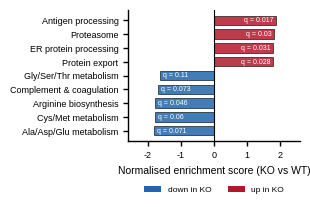

Saved: Fig3D_KO_pathway_enrichment_v1_manual.pdf (prior manual version)


In [4]:
# Curated subset of KEGG GSEA terms shown in the main-figure panel (representative terms spanning the
# down-in-KO amino-acid/nitrogen-metabolism signal and the up-in-KO proteostasis signal); the full KEGG
# GSEA result (all tested terms) feeds Table S6 below.
KEGG_TERMS_FIG3D = ['Alanine, aspartate and glutamate metabolism', 'Arginine biosynthesis',
                    'Cysteine and methionine metabolism', 'Glycine, serine and threonine metabolism',
                    'Complement and coagulation cascades', 'Proteasome',
                    'Protein processing in endoplasmic reticulum', 'Protein export',
                    'Antigen processing and presentation']
df = res_kegg_gsea.loc[KEGG_TERMS_FIG3D, ['NES', 'FDR q-val']].reset_index().rename(
    columns={'Term': 'pathway', 'FDR q-val': 'FDR_q'})
df = df.sort_values('NES')                      # most negative at bottom -> drawn top-down
def fdr(q): return f'q = {q:.2g}'

# short labels so the panel fits compactly in the multi-panel Fig 3 layout (same abbreviations used
# for the term-block labels in the leading-edge supplementary panels below)
SHORT_LABEL = {
    'Alanine, aspartate and glutamate metabolism': 'Ala/Asp/Glu metabolism',
    'Arginine biosynthesis': 'Arginine biosynthesis',
    'Cysteine and methionine metabolism': 'Cys/Met metabolism',
    'Glycine, serine and threonine metabolism': 'Gly/Ser/Thr metabolism',
    'Complement and coagulation cascades': 'Complement & coagulation',
    'Proteasome': 'Proteasome',
    'Protein processing in endoplasmic reticulum': 'ER protein processing',
    'Protein export': 'Protein export',
    'Antigen processing and presentation': 'Antigen processing',
}

y = np.arange(len(df))
fig, ax = plt.subplots(figsize=(3.2, 2.3))
for yi, (_, r) in zip(y, df.iterrows()):
    ax.barh(yi, r['NES'], color=(C_DOWN if r['NES'] < 0 else C_UP), alpha=0.85,
            edgecolor='black', linewidth=0.5, height=0.68, zorder=2)
    ax.text(r['NES']-0.08 if r['NES']>0 else r['NES']+0.08, yi, fdr(r['FDR_q']),
            va='center', ha='right' if r['NES']>0 else 'left', fontsize=5, color='white')
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels([SHORT_LABEL[p] for p in df['pathway']], fontsize=6.5)
ax.set_xlabel('Normalised enrichment score (KO vs WT)', fontsize=7.5)
ax.set_xlim(-2.6, 2.6)
ax.tick_params(axis='both', labelsize=6.5)
ax.legend(handles=[Patch(facecolor=C_DOWN, label='down in KO'), Patch(facecolor=C_UP, label='up in KO')],
          frameon=False, fontsize=6, loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=2)
plt.tight_layout()
fig.savefig('Fig3D_KO_pathway_enrichment_v1_manual.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig3D_KO_pathway_enrichment_v1_manual.pdf (prior manual version)')


## Panel 3D, automated: cross-method deduplication + pre-registered category filter

**This is the version used in the manuscript.** The manually-curated 9-term panel above is retained only
as a record of what was previously shown. The pipeline below has two stages, and does not read from any
hand-built gene set:

**Stage 1 -- deduplicate across methods.** The same underlying signal is often re-detected under different
names by different libraries (e.g. KEGG's *Arginine biosynthesis* and *Alanine, aspartate and glutamate
metabolism* share most of their leading-edge genes). Reporting near-duplicates as if they were independent
findings inflates the apparent number of hits. This is fixed with the same Kappa-statistic gene-overlap
clustering that Metascape and DAVID use internally (Huang et al. 2007 *Nucleic Acids Res*; Zhou et al. 2019
*Nat Commun*): every significant term across **KEGG GSEA and Hallmark GSEA** is compared pairwise by the
overlap of its leading-edge genes (Cohen's kappa, over the 14,108-gene tested background), clustered at the
standard kappa >= 0.3 threshold, and one representative (lowest FDR q) is kept per cluster.

This notebook's own hand-curated modules (`slc38a4_curated_modules.gmt`, incl. the urea-cycle/nitrogen
module) are **not** part of this pool -- a hand-built gene set is itself a curated object, so mixing it into
an "unbiased" pipeline would defeat the point. The curated urea-cycle module is instead reported on its own,
as a classic GSEA enrichment plot, in the urea-cycle section below.

**Reactome GSEA is also excluded from this clustering step** -- tested and found to break it. Reactome's
~1,000 pathways are deeply nested (a pathway and its parent routinely share 80-90% of genes by
construction), so pooling it in collapses *Proteasome*, *DNA replication*, *apoptosis* and *antigen
presentation* into one 100+ term cluster even at kappa >= 0.6 -- an artifact of Reactome's hierarchy, not a
real shared signal. Reactome results remain fully available in the reviewer-facing outputs above; they are
just not used to decide what belongs in this panel.

**Stage 2 -- the pre-registered category filter** is applied to the *deduplicated* list: every term/cluster
that (a) falls in one of the three categories fixed before looking at results and (b) clears FDR q < 0.25
is shown; nothing else is.


In [5]:
# ---- Stage 1: cross-method deduplication (Kappa-statistic clustering, KEGG + Hallmark GSEA only) ----
# No hand-built gene set is part of this pool -- see the markdown above for why the curated modules
# (incl. Urea_cycle_nitrogen) and Reactome GSEA are both deliberately excluded.
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

UNIVERSE_N = de_raw['gene_symbol'].dropna().astype(str).nunique()  # 14,108 genes tested

def _load_gsea_for_dedup(result_df, library):
    d = result_df.dropna(subset=['NES', 'FDR q-val']).copy()
    d = d[d['FDR q-val'] < 0.25]
    d['library'] = library
    d['gene_set'] = d['Lead_genes'].fillna('').apply(lambda s: set(s.split(';')) if s else set())
    return d[['NES', 'FDR q-val', 'library', 'gene_set']].reset_index().rename(columns={'index': 'term', 'Name': 'term'})

def _kappa(set_a, set_b, n):
    a = len(set_a & set_b); b = len(set_a - set_b); c = len(set_b - set_a); d = n - a - b - c
    po = (a + d) / n
    pe = ((a + b) / n) * ((a + c) / n) + ((c + d) / n) * ((b + d) / n)
    return 0.0 if pe >= 1 else (po - pe) / (1 - pe)

_pool = pd.concat([
    _load_gsea_for_dedup(res_kegg_gsea, 'KEGG'),
    _load_gsea_for_dedup(res_hallmark, 'Hallmark'),
], ignore_index=True)
if 'term' not in _pool.columns:
    _pool = _pool.rename(columns={_pool.columns[0]: 'term'})

_n = len(_pool)
_K = np.zeros((_n, _n))
for _i in range(_n):
    for _j in range(_i + 1, _n):
        _K[_i, _j] = _K[_j, _i] = _kappa(_pool['gene_set'].iloc[_i], _pool['gene_set'].iloc[_j], UNIVERSE_N)
_dist = np.clip(1 - _K, 0, None)
np.fill_diagonal(_dist, 0)
_Z = linkage(squareform(_dist, checks=False), method='complete')  # complete linkage: avoids chaining distinct themes together
KAPPA_THRESHOLD = 0.3  # standard DAVID/Metascape default
_pool['cluster'] = fcluster(_Z, t=1 - KAPPA_THRESHOLD, criterion='distance')

dedup_terms = _pool.loc[_pool.groupby('cluster')['FDR q-val'].idxmin()].reset_index(drop=True)
dedup_terms['cluster_members'] = dedup_terms['cluster'].map(
    lambda c: _pool.loc[_pool['cluster'] == c, ['term', 'library']].values.tolist())

print(f'{len(_pool)} significant terms (KEGG+Hallmark, FDR q<0.25) -> '
      f'{len(dedup_terms)} non-redundant clusters (kappa>={KAPPA_THRESHOLD}, complete linkage)')
_merged = dedup_terms[dedup_terms['cluster_members'].apply(len) > 1]
print(f'{len(_merged)} clusters merged >1 term -- cross-method agreement, not narrative selection:')
for _, r in _merged.sort_values('NES').iterrows():
    other = [m for m in r['cluster_members'] if m[0] != r['term']]
    print(f"  {r['term']:45s} ({r['library']})  absorbed: {other}")


107 significant terms (KEGG+Hallmark, FDR q<0.25) -> 84 non-redundant clusters (kappa>=0.3, complete linkage)
19 clusters merged >1 term -- cross-method agreement, not narrative selection:
  Arginine biosynthesis                         (KEGG)  absorbed: [['Alanine, aspartate and glutamate metabolism', 'KEGG']]
  Complement and coagulation cascades           (KEGG)  absorbed: [['Complement', 'Hallmark'], ['Coagulation', 'Hallmark']]
  GABAergic synapse                             (KEGG)  absorbed: [['Glutamatergic synapse', 'KEGG']]
  Insulin resistance                            (KEGG)  absorbed: [['Adipocytokine signaling pathway', 'KEGG']]
  Coronavirus disease                           (KEGG)  absorbed: [['Ribosome', 'KEGG']]
  IL-6/JAK/STAT3 Signaling                      (Hallmark)  absorbed: [['Cytokine-cytokine receptor interaction', 'KEGG']]
  Glycolysis                                    (Hallmark)  absorbed: [['Hypoxia', 'Hallmark']]
  Chronic myeloid leukemia               

In [6]:
# ---- Stage 2: pre-registered category filter, applied to the deduplicated list ----
KEGG_PANEL_CATEGORIES = {
    'Amino-acid / nitrogen metabolism (SLC38A4 substrate-adjacent)': [
        'Alanine, aspartate and glutamate metabolism', 'Arginine biosynthesis',
        'Cysteine and methionine metabolism', 'Glycine, serine and threonine metabolism',
    ],
    'Hepatocyte synthetic function': [
        'Complement and coagulation cascades',
    ],
    'Proteostasis / antigen handling': [
        'Proteasome', 'Protein processing in endoplasmic reticulum',
        'Protein export', 'Antigen processing and presentation',
    ],
}
ALLOWLIST = [t for terms in KEGG_PANEL_CATEGORIES.values() for t in terms]

def _cluster_touches_allowlist(members):
    return any(name in ALLOWLIST for name, _lib in members)

panel_terms = dedup_terms[dedup_terms['cluster_members'].apply(_cluster_touches_allowlist)].sort_values('NES').reset_index(drop=True)
print(f'Panel 3D (final): {len(panel_terms)} non-redundant, allow-listed terms:')
for _, r in panel_terms.iterrows():
    other = [m for m in r['cluster_members'] if m[0] != r['term']]
    tag = f"  <- absorbed {other}" if other else ''
    print(f"  [{r['library']:>8}] {r['term']:45s} NES={r['NES']:+.2f} q={r['FDR q-val']:.3g}{tag}")

WATCH_ADJACENT = ['Aminoacyl-tRNA biosynthesis']  # on-topic but outside the allow-list; not auto-included
_watch = dedup_terms[dedup_terms['term'].isin(WATCH_ADJACENT)]
if len(_watch):
    print('\nOn-topic term sitting just outside the allow-list (not auto-included -- flagged, not hidden):')
    print(_watch[['term', 'library', 'NES', 'FDR q-val']].to_string(index=False))


Panel 3D (final): 8 non-redundant, allow-listed terms:
  [    KEGG] Cysteine and methionine metabolism            NES=-1.79 q=0.0596
  [    KEGG] Arginine biosynthesis                         NES=-1.79 q=0.0459  <- absorbed [['Alanine, aspartate and glutamate metabolism', 'KEGG']]
  [    KEGG] Complement and coagulation cascades           NES=-1.69 q=0.0729  <- absorbed [['Complement', 'Hallmark'], ['Coagulation', 'Hallmark']]
  [    KEGG] Glycine, serine and threonine metabolism      NES=-1.62 q=0.108
  [    KEGG] Protein export                                NES=+1.78 q=0.0283
  [    KEGG] Protein processing in endoplasmic reticulum   NES=+1.78 q=0.0313
  [    KEGG] Proteasome                                    NES=+1.81 q=0.0301
  [    KEGG] Antigen processing and presentation           NES=+1.88 q=0.0171

On-topic term sitting just outside the allow-list (not auto-included -- flagged, not hidden):
                       term library       NES  FDR q-val
Aminoacyl-tRNA biosynthesis 

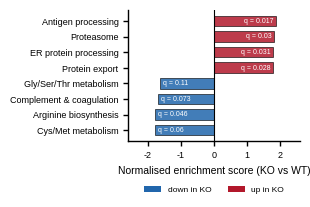

Saved: Fig3D_KO_pathway_enrichment.pdf (8 terms, automated pipeline)


In [7]:
# ---- Panel 3D, final: automated, cross-method-deduplicated, no hand-built gene sets ----
# Formatted to match the prior manually-curated panel exactly (size, styling, in-bar q-value labels).
SHORT_LABEL = {
    'Alanine, aspartate and glutamate metabolism': 'Ala/Asp/Glu metabolism',
    'Arginine biosynthesis': 'Arginine biosynthesis',
    'Cysteine and methionine metabolism': 'Cys/Met metabolism',
    'Glycine, serine and threonine metabolism': 'Gly/Ser/Thr metabolism',
    'Complement and coagulation cascades': 'Complement & coagulation',
    'Proteasome': 'Proteasome',
    'Protein processing in endoplasmic reticulum': 'ER protein processing',
    'Protein export': 'Protein export',
    'Antigen processing and presentation': 'Antigen processing',
}
def fdr(q): return f'q = {q:.2g}'

y = np.arange(len(panel_terms))
fig, ax = plt.subplots(figsize=(3.2, 2.3))
for yi, (_, r) in zip(y, panel_terms.iterrows()):
    ax.barh(yi, r['NES'], color=(C_DOWN if r['NES'] < 0 else C_UP), alpha=0.85,
            edgecolor='black', linewidth=0.5, height=0.68, zorder=2)
    ax.text(r['NES']-0.08 if r['NES']>0 else r['NES']+0.08, yi, fdr(r['FDR q-val']),
            va='center', ha='right' if r['NES']>0 else 'left', fontsize=5, color='white')
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels([SHORT_LABEL.get(p, p) for p in panel_terms['term']], fontsize=6.5)
ax.set_xlabel('Normalised enrichment score (KO vs WT)', fontsize=7.5)
ax.set_xlim(-2.6, 2.6)
ax.tick_params(axis='both', labelsize=6.5)
ax.legend(handles=[Patch(facecolor=C_DOWN, label='down in KO'), Patch(facecolor=C_UP, label='up in KO')],
          frameon=False, fontsize=6, loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=2)
plt.tight_layout()
fig.savefig('Fig3D_KO_pathway_enrichment.pdf', bbox_inches='tight')
plt.show()
print(f'Saved: Fig3D_KO_pathway_enrichment.pdf ({len(panel_terms)} terms, automated pipeline)')


## Table S6 — full cross-method pathway-enrichment results

The curated bars above are drawn from a subset of representative terms; Table S6 reports the full
cross-method concordance (KEGG/Reactome/GO over-representation and pre-ranked GSEA) referenced in
the text ("This pattern was concordant across independent databases and methods").


In [8]:
def _ora_rows(df, method_label, direction, n=8):
    d = df.sort_values('Adjusted P-value').head(n)
    return pd.DataFrame({
        'Method': method_label, 'Direction': direction, 'Term': d['Term'].values,
        'Stat': [f'FDR={p:.1e}' for p in d['Adjusted P-value']],
        'Overlap': d['Overlap'].values,
        'Genes': [';'.join(str(g).split(';')[:6]) for g in d['Genes']],
    })

def _gsea_rows(df, method_label, direction, n=8):
    d = df.sort_values('NES', ascending=(direction == 'down')).head(n)
    return pd.DataFrame({
        'Method': method_label, 'Direction': direction, 'Term': d.index,
        'Stat': [f'NES={nes:+.2f}, FDR={fq:.2g}' for nes, fq in zip(d['NES'], d['FDR q-val'])],
        'Overlap': np.nan,
        'Genes': [';'.join(str(g).split(';')[:6]) for g in d['Lead_genes']],
    })

_go_bp = res_opt1_go[res_opt1_go['Gene_set'] == 'GO_Biological_Process_2023']
_go_mf = res_opt1_go[res_opt1_go['Gene_set'] == 'GO_Molecular_Function_2023']

summary = pd.concat([
    _ora_rows(res_opt2_kegg_up,    'KEGG (ORA)', 'up'),
    _ora_rows(res_opt2_kegg_down,  'KEGG (ORA)', 'down'),
    _ora_rows(res_opt4_react_up,   'Reactome (ORA)', 'up'),
    _ora_rows(res_opt4_react_down, 'Reactome (ORA)', 'down'),
    _ora_rows(_go_bp, 'GO:BP (ORA, down genes)', 'down'),
    _ora_rows(_go_mf, 'GO:MF (ORA, down genes)', 'down'),
    _gsea_rows(res_reactome_gsea, 'Reactome (GSEA)', 'up'),
    _gsea_rows(res_reactome_gsea, 'Reactome (GSEA)', 'down'),
    _gsea_rows(res_curated.loc[['Urea_cycle_nitrogen']], 'Curated (GSEA)', 'down', n=1),
    _gsea_rows(res_kegg_gsea, 'KEGG (GSEA)', 'up'),
    _gsea_rows(res_kegg_gsea, 'KEGG (GSEA)', 'down'),
    _gsea_rows(res_hallmark,  'Hallmark (GSEA)', 'up'),
    _gsea_rows(res_hallmark,  'Hallmark (GSEA)', 'down'),
], ignore_index=True)
ST6_PATH = 'Table_S6_KO_pathway_enrichment.xlsx'
_readme = pd.DataFrame({'Table S6 - Pathway enrichment, SLC38A4-KO vs WT (cross-method)': [
    'Enrichment of genes differentially expressed in SLC38A4-knockout Huh7.5 cells (KO vs WT).',
    'Methods: KEGG/Reactome/GO over-representation analysis (ORA) and pre-ranked GSEA (KEGG/Hallmark/Reactome), '
    'plus the hand-curated Urea_cycle_nitrogen module (slc38a4_curated_modules.gmt).',
    'Direction: "up"/"down" refers to the direction of the enriched gene set in the knockout.',
    'Genes column lists a representative subset of the leading-edge / overlapping genes per term.',
]})
with pd.ExcelWriter(ST6_PATH, engine='openpyxl') as xw:
    _readme.to_excel(xw, sheet_name='README', index=False)
    summary.to_excel(xw, sheet_name='enrichment_all_methods', index=False)
print(f'{len(summary)} term x method rows across methods: {sorted(summary["Method"].unique())}')
print(f'Saved: {ST6_PATH}')


97 term x method rows across methods: ['Curated (GSEA)', 'GO:BP (ORA, down genes)', 'GO:MF (ORA, down genes)', 'Hallmark (GSEA)', 'KEGG (GSEA)', 'KEGG (ORA)', 'Reactome (GSEA)', 'Reactome (ORA)']
Saved: Table_S6_KO_pathway_enrichment.xlsx


## All pathway-enrichment results, for reviewers

Fig 3D shows a curated 9-term subset of one of the 9 analyses run above, and Table S6 shows the top 8
hits per method/direction from each. Neither is the complete result. The two artefacts below are: an
overview figure giving every reviewer a fast visual read of all 9 analyses at once (top terms only, for
legibility), and a companion workbook with every tested term from every analysis, no top-N cutoff anywhere.
Nothing here was filtered for relevance to the manuscript's narrative -- it is the same 9 result objects
already sitting in memory above, shown in full.


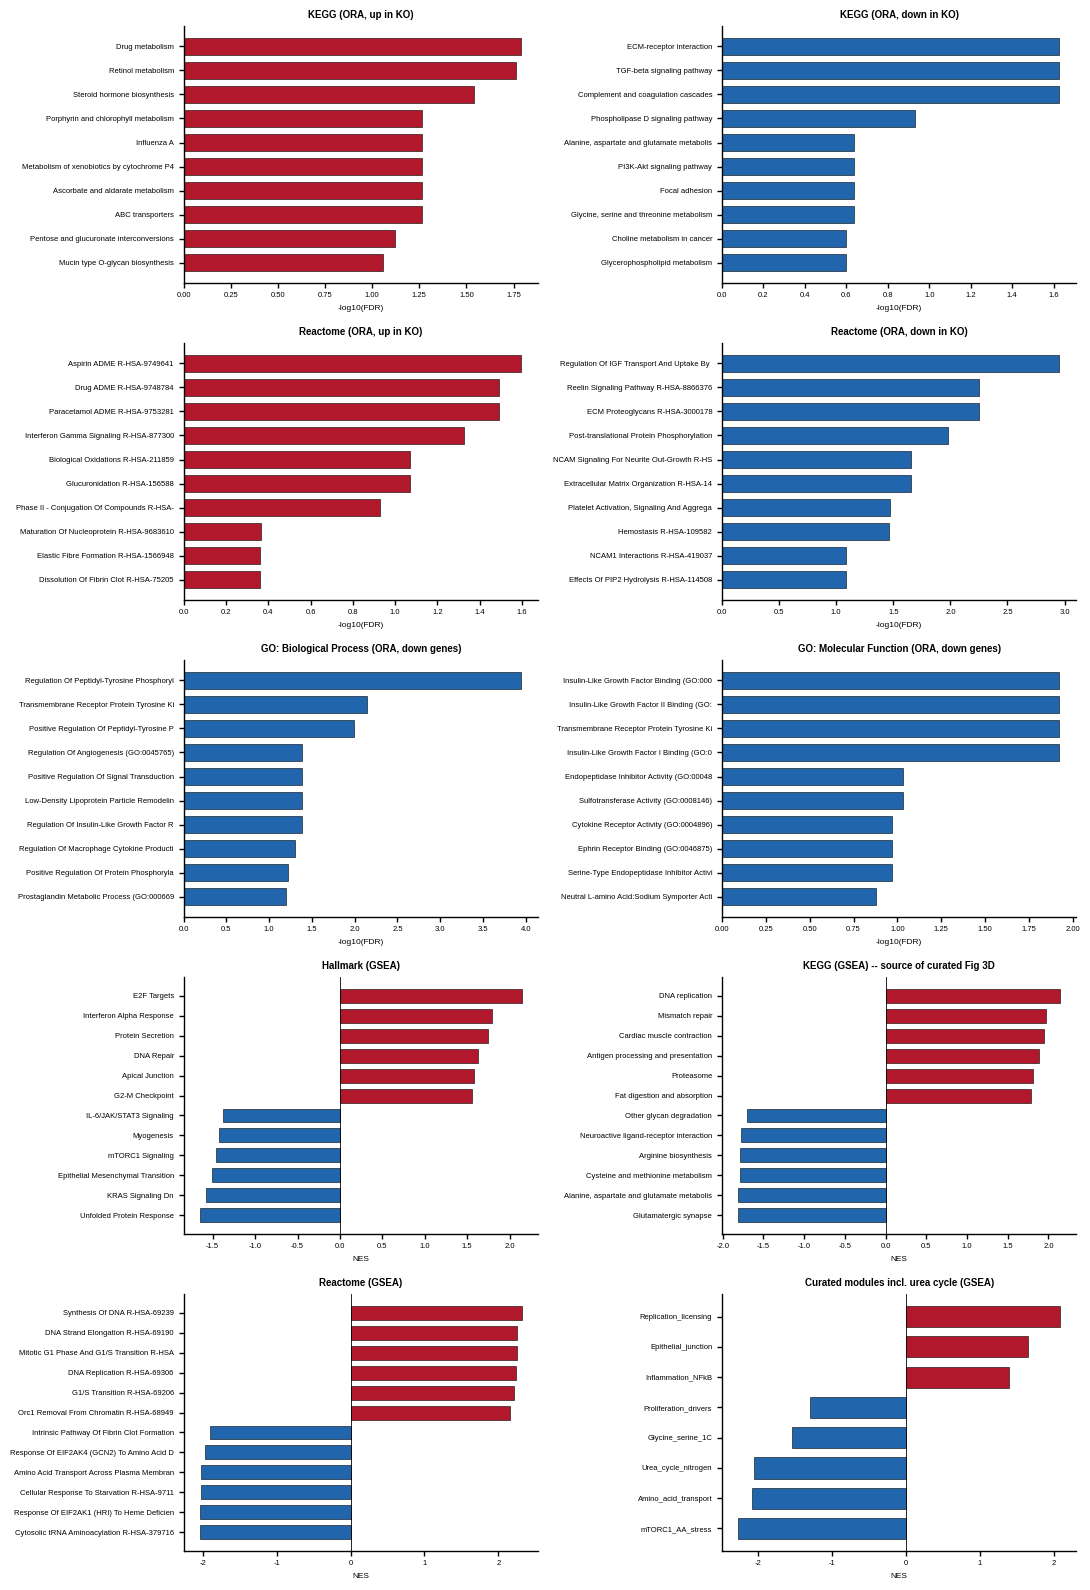

Saved: SuppFig_all_pathway_enrichment_overview.pdf (top terms only -- see the workbook below for every tested term).


In [9]:
# ---- Reviewer-facing overview: all 9 pathway-enrichment analyses, one panel each ----
from matplotlib.patches import Patch as _Patch

_go_bp = res_opt1_go[res_opt1_go['Gene_set'] == 'GO_Biological_Process_2023']
_go_mf = res_opt1_go[res_opt1_go['Gene_set'] == 'GO_Molecular_Function_2023']

def _plot_ora(ax, df, title, n=10, color=C_DOWN):
    d = df.sort_values('Adjusted P-value').head(n).iloc[::-1]
    y = np.arange(len(d))
    ax.barh(y, -np.log10(d['Adjusted P-value']), color=color, edgecolor='black', linewidth=0.4, height=0.7)
    ax.set_yticks(y); ax.set_yticklabels(d['Term'].str.slice(0, 42), fontsize=5.5)
    ax.set_xlabel('-log10(FDR)', fontsize=6); ax.set_title(title, fontsize=7, fontweight='bold')
    ax.tick_params(axis='x', labelsize=5.5)

def _plot_gsea(ax, df, title, n=12):
    d = df.dropna(subset=['NES', 'FDR q-val'])
    d = d[d['FDR q-val'] < 0.25]
    d = pd.concat([d.sort_values('NES').head(n // 2), d.sort_values('NES', ascending=False).head(n // 2)])
    d = d[~d.index.duplicated()].sort_values('NES')
    y = np.arange(len(d))
    colors = [C_DOWN if v < 0 else C_UP for v in d['NES']]
    ax.barh(y, d['NES'], color=colors, edgecolor='black', linewidth=0.4, height=0.7)
    ax.set_yticks(y); ax.set_yticklabels([str(t)[:42] for t in d.index], fontsize=5.5)
    ax.axvline(0, color='black', lw=0.6)
    ax.set_xlabel('NES', fontsize=6); ax.set_title(title, fontsize=7, fontweight='bold')
    ax.tick_params(axis='x', labelsize=5.5)

REVIEWER_PANELS = [
    ('KEGG (ORA, up in KO)',                     res_opt2_kegg_up,   'ora',  C_UP),
    ('KEGG (ORA, down in KO)',                   res_opt2_kegg_down, 'ora',  C_DOWN),
    ('Reactome (ORA, up in KO)',                 res_opt4_react_up,  'ora',  C_UP),
    ('Reactome (ORA, down in KO)',               res_opt4_react_down,'ora',  C_DOWN),
    ('GO: Biological Process (ORA, down genes)', _go_bp,             'ora',  C_DOWN),
    ('GO: Molecular Function (ORA, down genes)', _go_mf,             'ora',  C_DOWN),
    ('Hallmark (GSEA)',                          res_hallmark,       'gsea', None),
    ('KEGG (GSEA) -- source of curated Fig 3D',  res_kegg_gsea,      'gsea', None),
    ('Reactome (GSEA)',                          res_reactome_gsea,  'gsea', None),
    ('Curated modules incl. urea cycle (GSEA)',  res_curated,        'gsea', None),
]

fig, axes = plt.subplots(5, 2, figsize=(11, 16))
for ax, (title, df, kind, color) in zip(axes.flat, REVIEWER_PANELS):
    (_plot_ora(ax, df, title, color=color) if kind == 'ora' else _plot_gsea(ax, df, title))
plt.tight_layout()
fig.savefig('SuppFig_all_pathway_enrichment_overview.pdf', bbox_inches='tight')
plt.show()
print('Saved: SuppFig_all_pathway_enrichment_overview.pdf (top terms only -- see the workbook below for '
      'every tested term).')


In [10]:
# ---- Reviewer-facing export: every tested term, every analysis, no top-N cutoff ----
_export_sheets = {
    'KEGG_ORA_up':          res_opt2_kegg_up,
    'KEGG_ORA_down':        res_opt2_kegg_down,
    'Reactome_ORA_up':      res_opt4_react_up,
    'Reactome_ORA_down':    res_opt4_react_down,
    'GO_ORA_down_genes':    res_opt1_go,
    'Hallmark_GSEA':        res_hallmark.reset_index(),
    'KEGG_GSEA':            res_kegg_gsea.reset_index(),
    'Reactome_GSEA':        res_reactome_gsea.reset_index(),
    'Curated_modules_GSEA': res_curated.reset_index(),
}
_readme = pd.DataFrame({'README': [
    'Full, untruncated pathway-enrichment results underlying Fig 3D / Table S6 (SLC38A4-KO vs WT).',
    'Every term tested in every one of the 9 enrichment analyses run by this notebook -- no top-N cutoff.',
    'Fig 3D and Table S6 both show curated/top-N subsets of this data; this workbook is the complete '
    'underlying result, provided for reviewer transparency.',
    'One sheet per analysis. ORA sheets: Enrichr over-representation on the up/down DEG sets '
    '(FDR<0.05, |log2FC|>1). GSEA sheets: pre-ranked GSEA on the full moderated-t ranked gene list '
    '(seed=42, 1000 permutations).',
]})
with pd.ExcelWriter('Table_S6_extended_pathway_enrichment_ALL_terms.xlsx', engine='openpyxl') as _xl:
    _readme.to_excel(_xl, sheet_name='README', index=False)
    for _name, _df in _export_sheets.items():
        _df.to_excel(_xl, sheet_name=_name[:31], index=False)
print('Saved: Table_S6_extended_pathway_enrichment_ALL_terms.xlsx '
      f'({sum(len(d) for d in _export_sheets.values()):,} rows total across {len(_export_sheets)} sheets).')


Saved: Table_S6_extended_pathway_enrichment_ALL_terms.xlsx (8,089 rows total across 9 sheets).


## Fig S8A — leading-edge gene expression underlying Fig 3D

Two panels, generated and saved separately (as in the original figure assembly) then placed side by side
in Illustrator: **(A)** leading-edge gene log2 fold-changes (KO vs WT), grouped by the same 8 non-redundant
terms shown in Fig 3D; **(B)** the same genes' full expression heatmap (all replicates, row z-scored) with
a per-gene significance side-bar. Together they show the pathway signal is carried by genes that are
themselves strongly and significantly changed, even where the aggregate gene-set NES/FDR is more marginal.

Each group's genes are the **union of leading-edge genes across every gene set absorbed into that Fig 3D
cluster** (e.g. the "Arginine biosynthesis" bar in Fig 3D also absorbed *Alanine, aspartate and glutamate
metabolism*, so this panel's "Arginine biosynthesis" group draws from both). Genes are deduplicated across
groups (a gene claimed by an earlier group is not repeated); `TOP_N_PER_TERM` genes are shown per group,
ranked by |log2FC|.


### Panel A — leading-edge gene log2 fold-change, grouped by pathway


In [11]:
TOP_N_PER_TERM = 6   # leading-edge genes shown per Fig 3D group, ranked by |log2FC|; raise to show more

de_full = (pd.read_csv('Fig3C_limma_KO_vs_WT_combined_mincount10.csv', index_col=0)
             .dropna(subset=['gene_symbol']).drop_duplicates('gene_symbol').set_index('gene_symbol'))

TERM_LABEL_SHORT = {
    'Alanine, aspartate and glutamate metabolism': 'Ala/Asp/Glu metab.',
    'Arginine biosynthesis': 'Arginine biosynthesis',
    'Cysteine and methionine metabolism': 'Cys/Met metab.',
    'Glycine, serine and threonine metabolism': 'Gly/Ser/Thr metab.',
    'Complement and coagulation cascades': 'Complement & coagulation',
    'Proteasome': 'Proteasome',
    'Protein processing in endoplasmic reticulum': 'ER protein processing',
    'Protein export': 'Protein export',
    'Antigen processing and presentation': 'Antigen processing',
}

def _leadgenes(term, library):
    return set((res_kegg_gsea if library == 'KEGG' else res_hallmark).loc[term, 'Lead_genes'].split(';'))

used = set()
rows = []
for _, r in panel_terms.sort_values('NES', ascending=False).iterrows():
    members = r['cluster_members']
    genes = set()
    for name, lib in members:
        genes |= _leadgenes(name, lib)
    cand = de_full.reindex([g for g in genes if g in de_full.index])[['logFC', 'adj.P.Val']]
    cand = cand.reindex(cand['logFC'].abs().sort_values(ascending=False).index)   # ranked by |log2FC|
    label = TERM_LABEL_SHORT.get(r['term'], r['term']) + (f' (x{len(members)} sets)' if len(members) > 1 else '')
    chosen = 0
    for gene, rr in cand.iterrows():
        if gene in used:
            continue   # already claimed by an earlier (more up- or down-regulated) group
        rows.append({'group': label, 'gene': gene, 'logFC': rr['logFC'], 'FDR': rr['adj.P.Val']})
        used.add(gene); chosen += 1
        if chosen == TOP_N_PER_TERM:
            break

gh = pd.DataFrame(rows).iloc[::-1].reset_index(drop=True)   # first group at top
print(f'{len(gh)} unique gene rows across {gh["group"].nunique()} Fig 3D groups '
      f'(genes deduplicated across groups; groups noting "xN sets" absorbed N cross-method duplicates)')


48 unique gene rows across 8 Fig 3D groups (genes deduplicated across groups; groups noting "xN sets" absorbed N cross-method duplicates)


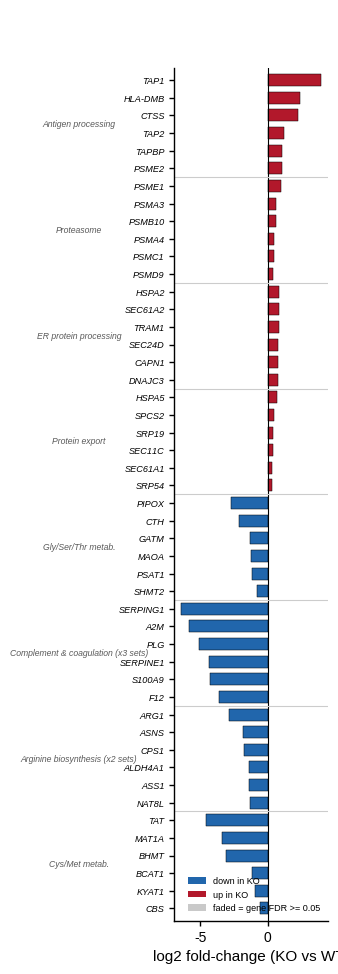

Saved: Fig_S8A_KO_leadingedge_bar.pdf  (panel A; row-aligned with panel B for Fig S8; 20% smaller, Helvetica)


In [12]:
y = np.arange(len(gh))
colors = [to_rgba(C_DOWN if v < 0 else C_UP, 1.0 if f < 0.05 else 0.35) for v, f in zip(gh['logFC'], gh['FDR'])]

# Blank spacer row above the bars, sized (empirically, via fig.get_tightbbox) to match the vertical
# space the sample-group strip takes above the heatmap in the companion panel (Fig_S8A-right_KO_leadingedge
# heatmap) -- so the two panels' gene rows land at the same absolute height when placed side by side as
# Fig S8 A/B. TOP_PAD_ROWS is in units of one gene-row; unchanged from the original version of this panel
# since it compensates for a fixed-height header element (the sample-group strip), not for gene count.
TOP_PAD_ROWS = 3.283
fig = plt.figure(figsize=(3.6, 0.185 * len(gh) + 0.3574 + 0.185 * TOP_PAD_ROWS))
gs = fig.add_gridspec(2, 1, height_ratios=[TOP_PAD_ROWS, len(gh)], hspace=0)
fig.add_subplot(gs[0, 0]).axis('off')   # blank spacer, no content
ax = fig.add_subplot(gs[1, 0])
ax.barh(y, gh['logFC'], height=0.68, color=colors, edgecolor='black', linewidth=0.35, zorder=2)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(gh['gene'], fontsize=6.6, fontstyle='italic')

# group-block dividers + labels in the left margin (same convention as Fig 3H)
prev = None
for i, g in enumerate(gh['group']):
    if g != prev and i > 0:
        ax.axhline(i - 0.5, color='0.8', lw=0.8)
    prev = g
tr = ax.get_yaxis_transform()
for g in gh['group'].unique():
    idx = np.where(gh['group'] == g)[0]
    ax.text(-0.62, (idx.min() + idx.max()) / 2, g, transform=tr, fontsize=6.2,
            style='italic', va='center', ha='center', rotation=0, color='0.35', clip_on=False)
fig.subplots_adjust(left=0.42)

ax.set_xlabel('log2 fold-change (KO vs WT)', fontsize=AXTITLE)
ax.set_ylim(-0.7, len(gh) - 0.3)
ax.legend(handles=[Patch(facecolor=C_DOWN, label='down in KO'), Patch(facecolor=C_UP, label='up in KO'),
                   Patch(facecolor='0.4', alpha=0.35, label='faded = gene FDR >= 0.05')],
          fontsize=6.5, frameon=False, loc='lower right')
plt.tight_layout()
FIG_S8A = 'Fig_S8A_KO_leadingedge_bar.pdf'
_tmp_path = '/tmp/_' + FIG_S8A
fig.savefig(_tmp_path, bbox_inches='tight'); plt.show()

# Shrink by 20% (pure vector page-scale -- every font size, line width and margin scales together, so
# nothing looks disproportionate) so it drops straight into an Illustrator layout at 100% alongside its
# companion panel. Scaled in a local temp path, then copied to the final name in one write -- reading a
# file back immediately after writing it on this OneDrive-synced folder hits a real sync delay.
import shutil
from pypdf import PdfReader, PdfWriter
_r = PdfReader(_tmp_path); _w = PdfWriter()
_p = _r.pages[0]; _p.scale_by(0.8); _w.add_page(_p)
with open(_tmp_path, 'wb') as _f: _w.write(_f)
shutil.copyfile(_tmp_path, FIG_S8A)

print(f'Saved: {FIG_S8A}  (panel A; row-aligned with panel B for Fig S8; 20% smaller, Helvetica)')


### Panel B — expression heatmap (all replicates) with a significance side-bar

A per-sample expression heatmap for the same (deduplicated) leading-edge genes shown in panel A — all
replicates per group shown individually, not just group means — row-standardised (z-score) so patterns are
comparable across genes of very different absolute expression. A narrow side-bar to the right of the
heatmap encodes each gene's own significance (KO-vs-WT, combined; -log10 FDR).


In [13]:
expr = pd.read_csv('Fig3B_voom_logCPM_mincount10.csv', index_col=0)
sample_cols = [c for c in expr.columns if c not in ('ensembl_id', 'gene_symbol')]
def grp(s): return 'WT' if s.startswith('SCWT') else ('KO1' if s.startswith('C12') else 'KO2')
GRP_ORDER = ['WT', 'KO1', 'KO2']
GRP_COLORS = {'WT': '#AAAAAA', 'KO1': '#D73027', 'KO2': '#FC8D59'}   # same group palette used elsewhere
samples_ordered = sorted(sample_cols, key=lambda s: (GRP_ORDER.index(grp(s)), s))
sample_grp = [grp(s) for s in samples_ordered]

# same genes / same order as panel A above (gh: group, gene, logFC, FDR)
expr_idx = expr.set_index('gene_symbol')
hm = expr_idx.loc[gh['gene'], samples_ordered].copy()
hm_z = hm.sub(hm.mean(axis=1), axis=0).div(hm.std(axis=1, ddof=1), axis=0)   # row z-score
sig = gh['FDR'].apply(lambda q: -np.log10(max(q, 1e-300))).values


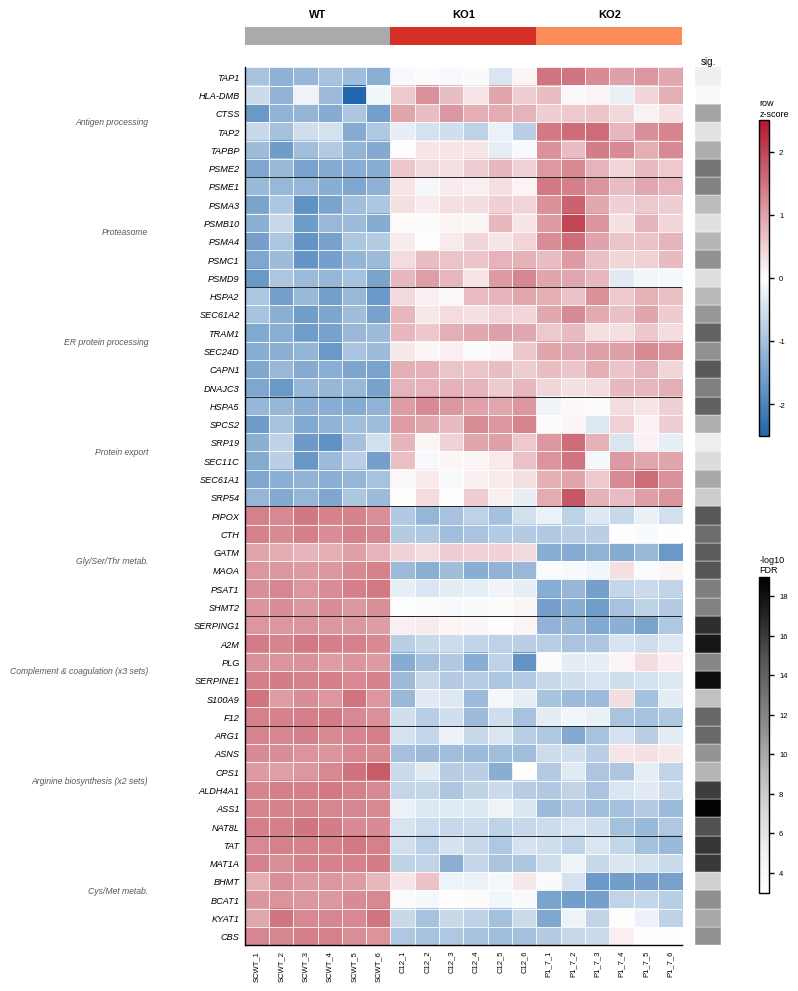

Saved: Fig_S8A-right_KO_leadingedge_heatmap.pdf  (panel B; 48 genes x 18 samples; 20% smaller, Helvetica)


In [14]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import Normalize

CMAP_EXPR = LinearSegmentedColormap.from_list('down_white_up', [C_DOWN, 'white', C_UP])
ZLIM = 2.5   # z-score colour scale cap

n_genes, n_samples = hm_z.shape
fig = plt.figure(figsize=(7.6, 0.185 * n_genes + 3.05))   # row height (0.185in/gene) matched to
                                                      # panel A (Fig_S8A_KO_leadingedge_bar) so
                                                      # the two panels come out the same overall
                                                      # height for side-by-side placement as Fig
                                                      # S8 A/B; offset unchanged from the original
                                                      # version of this panel.
gs = fig.add_gridspec(2, 4, width_ratios=[n_samples, 1.1, 0.5, 0.75], height_ratios=[1, n_genes],
                       hspace=0.05, wspace=0.10)

ax_grp = fig.add_subplot(gs[0, 0])
for j, g in enumerate(sample_grp):
    ax_grp.add_patch(plt.Rectangle((j - 0.5, 0), 1, 1, color=GRP_COLORS[g], lw=0))
ax_grp.set_xlim(-0.5, n_samples - 0.5); ax_grp.set_ylim(0, 1)
ax_grp.set_xticks([]); ax_grp.set_yticks([])
for sp in ax_grp.spines.values(): sp.set_visible(False)
for g in GRP_ORDER:
    idx = [j for j, gg in enumerate(sample_grp) if gg == g]
    ax_grp.text((min(idx) + max(idx)) / 2, 1.4, g, ha='center', va='bottom', fontsize=8, fontweight='bold')

ax_heat = fig.add_subplot(gs[1, 0])
im = ax_heat.imshow(hm_z.values, aspect='auto', cmap=CMAP_EXPR, vmin=-ZLIM, vmax=ZLIM, origin='lower')
ax_heat.set_xticks(np.arange(-0.5, n_samples, 1), minor=True)
ax_heat.set_yticks(np.arange(-0.5, n_genes, 1), minor=True)
ax_heat.grid(which='minor', color='white', linewidth=0.6)
ax_heat.tick_params(which='minor', bottom=False, left=False)
ax_heat.set_xticks(range(n_samples)); ax_heat.set_xticklabels(samples_ordered, rotation=90, fontsize=5.5)
ax_heat.set_yticks(range(n_genes)); ax_heat.set_yticklabels(gh['gene'], fontsize=6.6, fontstyle='italic')
ax_heat.tick_params(axis='both', which='major', length=0)

prev = None
for i, g in enumerate(gh['group']):
    if g != prev and i > 0:
        ax_heat.axhline(i - 0.5, color='black', lw=0.6)
    prev = g
tr = ax_heat.get_yaxis_transform()
for g in gh['group'].unique():
    idx = np.where(gh['group'] == g)[0]
    ax_heat.text(-0.22, (idx.min() + idx.max()) / 2, g, transform=tr, fontsize=6.2,
                 style='italic', va='center', ha='right', color='0.35', clip_on=False)
fig.subplots_adjust(left=0.20)

ax_sig = fig.add_subplot(gs[1, 1])
SIG_VMIN, SIG_VMAX = 3, 19
sig_norm = Normalize(vmin=SIG_VMIN, vmax=SIG_VMAX)
sig_cmap = plt.get_cmap('Greys')
for i, v in enumerate(sig):
    ax_sig.add_patch(plt.Rectangle((0, i - 0.5), 1, 1, facecolor=sig_cmap(sig_norm(v)),
                                    edgecolor='white', linewidth=0.3))
ax_sig.set_xlim(0, 1); ax_sig.set_ylim(-0.5, len(sig) - 0.5)
ax_sig.set_xticks([]); ax_sig.set_yticks([])
ax_sig.set_title('sig.', fontsize=7, pad=2)
for sp in ax_sig.spines.values(): sp.set_visible(False)

ax_cb_col = fig.add_subplot(gs[1, 3])
ax_cb_col.axis('off')

cax1 = ax_cb_col.inset_axes((0.05, 0.58, 0.55, 0.36))
fig.colorbar(im, cax=cax1, orientation='vertical')
cax1.set_title('row\nz-score', fontsize=6.5, pad=3, loc='left')
cax1.tick_params(labelsize=5.5)

sm = plt.cm.ScalarMappable(cmap=sig_cmap, norm=sig_norm)
sm.set_array([])
cax2 = ax_cb_col.inset_axes((0.05, 0.06, 0.55, 0.36))
fig.colorbar(sm, cax=cax2, orientation='vertical')
cax2.set_title('-log10\nFDR', fontsize=6.5, pad=3, loc='left')
cax2.tick_params(labelsize=5.5)

FIG_S8A_RIGHT = 'Fig_S8A-right_KO_leadingedge_heatmap.pdf'
_tmp_path = '/tmp/_' + FIG_S8A_RIGHT
fig.savefig(_tmp_path, bbox_inches='tight'); plt.show()

# Shrink by 20%, same pure vector page-scale as panel A (see that cell for why it's done via a local
# temp path), so both drop into Illustrator at 100% already sized to sit side by side.
import shutil
from pypdf import PdfReader, PdfWriter
_r = PdfReader(_tmp_path); _w = PdfWriter()
_p = _r.pages[0]; _p.scale_by(0.8); _w.add_page(_p)
with open(_tmp_path, 'wb') as _f: _w.write(_f)
shutil.copyfile(_tmp_path, FIG_S8A_RIGHT)

print(f'Saved: {FIG_S8A_RIGHT}  (panel B; {n_genes} genes x {n_samples} samples; 20% smaller, Helvetica)')


## Urea-cycle gene expression underlying reduced ureagenesis

Urea-cycle enzymes and mitochondrial carriers (limma-voom, min.count = 10), coloured by SLC38A4-KO vs WT
log2FC. This is Fig 3E. It pairs with the ureagenesis functional assay (Fig 3F): the coordinated
transcriptional downregulation of the cycle shown here provides the molecular basis for the reduced urea
output measured directly in Fig 3F.

Three views from one tidy table (`ug`, saved as `Fig3E_urea_cycle_gene_data.csv`): **(main, Fig 3E)** pathway
schematic, KO log2FC only, laid out along the actual biochemical route -- replaces the flat bar chart used in
an earlier draft, since a linear pathway like this one is easier to read as a diagram than as a series of
bars; **(reviewer companion, unnumbered)** paired bar chart, KO vs SAH-liver (InTEAM DESeq2, SAH vs normal)
concordance, same convention as Fig S8A for Fig 3D -- kept for direct gene-level comparison but not
itself one of the numbered supplementary figures (Fig S8B is the cross-clone GSEA reproducibility
forest plot, generated in the clone-robustness-check notebook); **(reviewer check)** the flat KO-only bar chart Fig 3E used previously,
kept unnumbered for direct numeric comparison against the schematic. Full opacity/solid = FDR < 0.05;
faded/dashed = not significant.


### Enrichment analyses flagging urea-cycle / nitrogen-metabolism terms

Which of the 9 pathway-enrichment analyses computed above (ORA + GSEA, incl. the hand-curated
`Urea_cycle_nitrogen` module) flag the urea cycle or closely related concepts (urea, arginine, ornithine,
nitrogen, citrulline)? This searches every tested term across all 9 analyses, not just the curated subset
shown in Fig 3D / Table S6.

### Classic GSEA enrichment plot — curated urea-cycle/nitrogen module

This hand-curated gene set (`Urea_cycle_nitrogen` in `slc38a4_curated_modules.gmt`) previously supplied one
of the bars in Fig 3D. It no longer does -- Fig 3D is now built only from KEGG and Hallmark GSEA, with no
hand-built gene set feeding it (see "Panel 3D, automated" above for why). The module is retained here
instead, reported on its own as the standard/classic GSEA running-enrichment-score plot rather than folded
into a bar chart alongside independently-detected hits, so a hand-curated result isn't visually equivalent
to the automated ones. It corroborates the same signal Fig 3D shows from KEGG's *Arginine biosynthesis* /
*Alanine, aspartate and glutamate metabolism* alone.


In [15]:
# ---- Classic GSEA plot: curated urea-cycle/nitrogen module, run fresh (always live, no cache) ----
import gseapy as gp
_g_urea = gp.prerank(rnk=ranked, gene_sets='slc38a4_curated_modules.gmt', min_size=5, max_size=500,
                      permutation_num=1000, outdir=None, seed=42, verbose=False, no_plot=True)
_r_urea = _g_urea.results['Urea_cycle_nitrogen']
print(f"Urea_cycle_nitrogen: NES={_r_urea['nes']:+.3f}  p={_r_urea['pval']:.3g}  FDR={_r_urea['fdr']:.3g}  "
      f"({len(_r_urea['hits'])} leading-edge genes)")

FIG_UREA_GSEA = 'FigS_urea_cycle_GSEA_classic.pdf'
gp.gseaplot(term='Urea cycle / nitrogen metabolism (curated)', hits=_r_urea['hits'], nes=_r_urea['nes'],
            pval=_r_urea['pval'], fdr=_r_urea['fdr'], RES=_r_urea['RES'], rank_metric=_g_urea.ranking.values,
            color=C_DOWN, ofname=FIG_UREA_GSEA)
print(f'Saved: {FIG_UREA_GSEA}')


2026-08-14 13:36:47,225 [WARNING] Duplicated values found in preranked stats: 0.02% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


Urea_cycle_nitrogen: NES=-2.050  p=0  FDR=0  (17 leading-edge genes)


Saved: FigS_urea_cycle_GSEA_classic.pdf


In [16]:
KEYWORDS = ['urea', 'arginine', 'ornithine', 'nitrogen', 'citrulline', 'ureagenesis']
def _matches(term):
    return any(k in str(term).lower() for k in KEYWORDS)

ora_hits = []
for df, method, direction in [
    (res_opt1_go,         None,                'Downregulated in KO'),   # Gene_set column distinguishes library
    (res_opt2_kegg_up,    'KEGG (ORA)',        'Upregulated in KO'),
    (res_opt2_kegg_down,  'KEGG (ORA)',        'Downregulated in KO'),
    (res_opt4_react_up,   'Reactome (ORA)',    'Upregulated in KO'),
    (res_opt4_react_down, 'Reactome (ORA)',    'Downregulated in KO'),
]:
    hit = df[df['Term'].apply(_matches)].copy()
    if len(hit) == 0:
        continue
    hit['Method'] = hit['Gene_set'] + ' (ORA)' if method is None else method
    hit['Direction'] = direction
    hit['Significant'] = hit['Adjusted P-value'] < 0.05
    hit['Stat'] = hit['Adjusted P-value'].apply(lambda p: f'adj.P={p:.2g}')
    ora_hits.append(hit[['Method', 'Term', 'Direction', 'Stat', 'Significant', 'Genes']])
ora_hits = pd.concat(ora_hits, ignore_index=True) if ora_hits else pd.DataFrame()

gsea_hits = []
for df, method in [
    (res_curated,       'Curated modules (GSEA)'),
    (res_hallmark,      'Hallmark (GSEA)'),
    (res_kegg_gsea,      'KEGG (GSEA)'),
    (res_reactome_gsea,  'Reactome (GSEA)'),
]:
    hit = df[df.index.to_series().apply(_matches)].copy()
    if len(hit) == 0:
        continue
    hit = hit.reset_index().rename(columns={hit.index.name or 'index': 'Term'})
    hit['Method'] = method
    hit['Direction'] = hit['NES'].apply(lambda n: 'up in KO' if n > 0 else 'down in KO')
    hit['Significant'] = hit['FDR q-val'] < 0.25   # conventional GSEA significance threshold
    hit['Stat'] = hit.apply(lambda r: f"NES={r['NES']:+.2f}, FDR={r['FDR q-val']:.2g}", axis=1)
    hit = hit.rename(columns={'Lead_genes': 'Genes'})
    gsea_hits.append(hit[['Method', 'Term', 'Direction', 'Stat', 'Significant', 'Genes']])
gsea_hits = pd.concat(gsea_hits, ignore_index=True) if gsea_hits else pd.DataFrame()

urea_hits = pd.concat([ora_hits, gsea_hits], ignore_index=True).sort_values(
    ['Significant', 'Method'], ascending=[False, True]).reset_index(drop=True)

# Annotate biological relevance -- several keyword matches are broad/generic GO terms or reflect a
# mechanistically distinct process (proteasome-mediated ODC turnover), not urea-cycle transcription itself.
NOTE = {
    'Arginine biosynthesis': 'direct urea-cycle/arginine pathway',
    'Urea_cycle_nitrogen': 'direct urea-cycle/nitrogen pathway (hand-curated gene set, slc38a4_curated_modules.gmt)',
    'Organonitrogen Compound Biosynthetic Process (GO:1901566)': 'broad GO term; only partial overlap with urea-cycle genes',
    'Nitrogen Compound Transport (GO:0071705)': 'broad GO term (general nitrogen-compound transporters, not urea-cycle enzymes)',
    'Regulation Of Ornithine Decarboxylase (ODC) R-HSA-350562': 'proteasome-mediated ODC turnover -- opposite direction; proteostasis, not urea-cycle transcription',
}
urea_hits['Note'] = urea_hits['Term'].map(NOTE).fillna('')

print(f'{len(urea_hits)} urea-cycle/nitrogen-keyword-matched term x method rows across all 9 original '
      f'ORA + GSEA analyses ({int(urea_hits["Significant"].sum())} significant).')
urea_hits[['Method', 'Term', 'Direction', 'Stat', 'Significant', 'Note']]

34 urea-cycle/nitrogen-keyword-matched term x method rows across all 9 original ORA + GSEA analyses (3 significant).


,Method,Term,Direction,Stat,Significant,Note
0,Curated modules (GSEA),Urea_cycle_nitrogen,down in KO,"NES=-2.05, FDR=0",True,direct urea-cycle/nitrogen pathway (hand-curat...
1,KEGG (GSEA),Arginine biosynthesis,down in KO,"NES=-1.79, FDR=0.046",True,direct urea-cycle/arginine pathway
2,Reactome (GSEA),Regulation Of Ornithine Decarboxylase (ODC) R-...,up in KO,"NES=+2.00, FDR=0.005",True,proteasome-mediated ODC turnover -- opposite d...
3,GO_Biological_Process_2023 (ORA),Citrulline Metabolic Process (GO:0000052),Downregulated in KO,adj.P=0.33,False,
4,GO_Biological_Process_2023 (ORA),Cellular Response To Organonitrogen Compound (...,Downregulated in KO,adj.P=0.38,False,
5,GO_Biological_Process_2023 (ORA),Organonitrogen Compound Biosynthetic Process (...,Downregulated in KO,adj.P=0.39,False,broad GO term; only partial overlap with urea-...
6,GO_Biological_Process_2023 (ORA),Arginine Metabolic Process (GO:0006525),Downregulated in KO,adj.P=0.44,False,
7,GO_Biological_Process_2023 (ORA),Positive Regulation Of Nitrogen Compound Metab...,Downregulated in KO,adj.P=0.61,False,
8,GO_Biological_Process_2023 (ORA),Urea Cycle (GO:0000050),Downregulated in KO,adj.P=0.61,False,
9,GO_Biological_Process_2023 (ORA),Organonitrogen Compound Catabolic Process (GO:...,Downregulated in KO,adj.P=0.62,False,


### Genes underlying the urea-cycle enrichment signal

The curated 15-gene urea-cycle/ureagenesis panel (below) is extended with any additional genes drawn from
the **direct** urea-cycle/arginine-pathway hits above -- KEGG GSEA "Arginine biosynthesis" and the curated
"Urea_cycle_nitrogen" gene set. The two broad GO:BP terms and the Reactome ODC/proteasome hit (flagged above)
are not urea-cycle enzymes and are not folded into this gene list.

In [17]:
CURATED_UREA_GENES = ['CPS1', 'NAGS', 'OTC', 'ASS1', 'ASL', 'ARG1', 'ARG2', 'SLC25A15', 'SLC25A13',
                      'GLUL', 'GLS', 'GOT1', 'GOT2', 'GPT2', 'ASNS', 'ALDH4A1', 'CAD']

DIRECT_HIT_GENES = set()
for term in ['Arginine biosynthesis', 'Urea_cycle_nitrogen']:
    rows_ = urea_hits[(urea_hits['Term'] == term) & (urea_hits['Significant'])]
    for g in rows_['Genes'].dropna():
        DIRECT_HIT_GENES.update(str(g).split(';'))
NEW_GENES = sorted(DIRECT_HIT_GENES - set(CURATED_UREA_GENES))
print(f'New gene(s) from the direct urea-cycle/arginine hits, not already in the curated panel: {NEW_GENES}')

ALL_UREA_GENES = CURATED_UREA_GENES + NEW_GENES

ko_full = (pd.read_csv('Fig3C_limma_KO_vs_WT_combined_mincount10.csv', index_col=0)
             .dropna(subset=['gene_symbol']).drop_duplicates('gene_symbol').set_index('gene_symbol'))
sah_full = (pd.read_csv('InTEAM_AH_vs_normal_DESeq2.csv')
              .dropna(subset=['symbol']).drop_duplicates('symbol').set_index('symbol'))

rows_ = []
for g in ALL_UREA_GENES:
    rows_.append({
        'gene': g,
        'source': 'curated urea-cycle/ureagenesis panel' if g in CURATED_UREA_GENES
                  else 'KEGG GSEA "Arginine biosynthesis" (added)',
        'ko_log2FC': ko_full.loc[g, 'logFC'] if g in ko_full.index else np.nan,
        'ko_FDR': ko_full.loc[g, 'adj.P.Val'] if g in ko_full.index else np.nan,
        'sah_log2FC': sah_full.loc[g, 'log2FoldChange'] if g in sah_full.index else np.nan,
        'sah_padj': sah_full.loc[g, 'padj'] if g in sah_full.index else np.nan,
    })
urea_gene_table = pd.DataFrame(rows_)
print(f'{len(urea_gene_table)} genes total ({len(CURATED_UREA_GENES)} curated + {len(NEW_GENES)} added from the '
      f'enrichment search above).')
urea_gene_table.round(4)

New gene(s) from the direct urea-cycle/arginine hits, not already in the curated panel: ['GLUD2']
18 genes total (17 curated + 1 added from the enrichment search above).


,gene,source,ko_log2FC,ko_FDR,sah_log2FC,sah_padj
0,CPS1,curated urea-cycle/ureagenesis panel,-1.7381,0.0000,-1.3760,0.0000
1,NAGS,curated urea-cycle/ureagenesis panel,-0.6943,0.0000,-0.5585,0.0131
2,OTC,curated urea-cycle/ureagenesis panel,0.3370,0.5664,-0.9624,0.0001
3,ASS1,curated urea-cycle/ureagenesis panel,-1.3918,0.0000,-2.2717,0.0000
4,ASL,curated urea-cycle/ureagenesis panel,0.1018,0.1073,-0.6195,0.0013
5,ARG1,curated urea-cycle/ureagenesis panel,-2.8279,0.0000,-1.2830,0.0000
6,ARG2,curated urea-cycle/ureagenesis panel,-0.1188,0.2860,0.2986,0.2280
7,SLC25A15,curated urea-cycle/ureagenesis panel,-0.8047,0.0000,-0.9264,0.0009
8,SLC25A13,curated urea-cycle/ureagenesis panel,-0.4555,0.0000,-1.3682,0.0000
9,GLUL,curated urea-cycle/ureagenesis panel,-0.2384,0.0001,-0.9219,0.0000


In [18]:
# Urea-cycle gene panel: genes are selected by PATHWAY MEMBERSHIP (KEGG/Reactome/established
# biochemistry), not by their own differential-expression result -- screening paralogues by whether
# they happen to be significant/concordant would bias the panel towards the result it is meant to show.
# For genes with tissue-restricted paralogues, BOTH are shown whenever BOTH are detected (i.e. pass
# low-count filtering) in this Huh7.5 RNA-seq dataset; a paralogue is excluded only when it is not
# measurably expressed here, never on the basis of its fold-change or significance.
CORE_GENES    = ['CPS1', 'NAGS', 'OTC', 'ASS1', 'ASL', 'ARG1']            # canonical cycle (KEGG hsa00220 / Reactome R-HSA-70635); NAGS = obligate CPS1 activator
CARRIER_GENES = ['SLC25A15', 'SLC25A13']                                   # mitochondrial carriers required for cycle flux
COUPLED_GENES = ['GOT1', 'GPT2', 'GLUL', 'GLS', 'ASNS', 'ALDH4A1', 'CAD']  # directly coupled nitrogen-handling enzymes
PARALOGS = {'ARG1': 'ARG2', 'GOT1': 'GOT2', 'GLS': 'GLS2', 'GPT2': 'GPT'}  # tissue-restricted paralogues to check for detection

detected = set(de_raw['gene_symbol'].dropna())
def _with_paralogs(genes):
    out = []
    for g in genes:
        out.append(g)
        if g in PARALOGS and PARALOGS[g] in detected:
            out.append(PARALOGS[g])
    return out

order = _with_paralogs(CORE_GENES) + CARRIER_GENES + _with_paralogs(COUPLED_GENES)
added_paralogs   = [p for p in PARALOGS.values() if p in detected]
dropped_paralogs = [p for p in PARALOGS.values() if p not in detected]
print(f'Paralogues detected in this dataset and added: {added_paralogs}')
print(f'Paralogues not detected here (excluded on that basis only, not on fold-change/significance): {dropped_paralogs}')

ko_idx  = de_raw.dropna(subset=['gene_symbol']).drop_duplicates('gene_symbol').set_index('gene_symbol')
sah_idx = (pd.read_csv('InTEAM_AH_vs_normal_DESeq2.csv')
             .dropna(subset=['symbol']).drop_duplicates('symbol').set_index('symbol'))

ug = pd.DataFrame([{
    'gene': g,
    'ko_log2FC': ko_idx.loc[g, 'logFC'],
    'ko_FDR': ko_idx.loc[g, 'adj.P.Val'],
    'sah_log2FC': sah_idx.loc[g, 'log2FoldChange'] if g in sah_idx.index else np.nan,
    'sah_FDR': sah_idx.loc[g, 'padj'] if g in sah_idx.index else np.nan,
} for g in order])
ug.to_csv('Fig3E_urea_cycle_gene_data.csv', index=False)   # regenerated transparently from raw data, not a static file
def op(fdr): return 1.0 if (pd.notna(fdr) and fdr < 0.05) else 0.35
print(f'{len(ug)} urea-cycle/nitrogen genes shown (Fig3E_urea_cycle_gene_data.csv regenerated)')


Paralogues detected in this dataset and added: ['ARG2', 'GOT2']
Paralogues not detected here (excluded on that basis only, not on fold-change/significance): ['GLS2', 'GPT']
17 urea-cycle/nitrogen genes shown (Fig3E_urea_cycle_gene_data.csv regenerated)


### Main panel -- urea-cycle pathway schematic (Fig 3E)

Enzymes and mitochondrial carriers are coloured by their KO-vs-WT log2FC; nodes are metabolites. OTC and ASL
are not significantly changed (n.s.). SLC25A13 is drawn as a dashed link and labelled separately from the
catalytic arrows, since it is the mitochondrial transporter that supplies aspartate for the ASS1 step, not
the enzyme that catalyses it -- SLC25A13 does not itself convert aspartate to argininosuccinate. Layout is
hand-placed; refine further in Illustrator if needed.


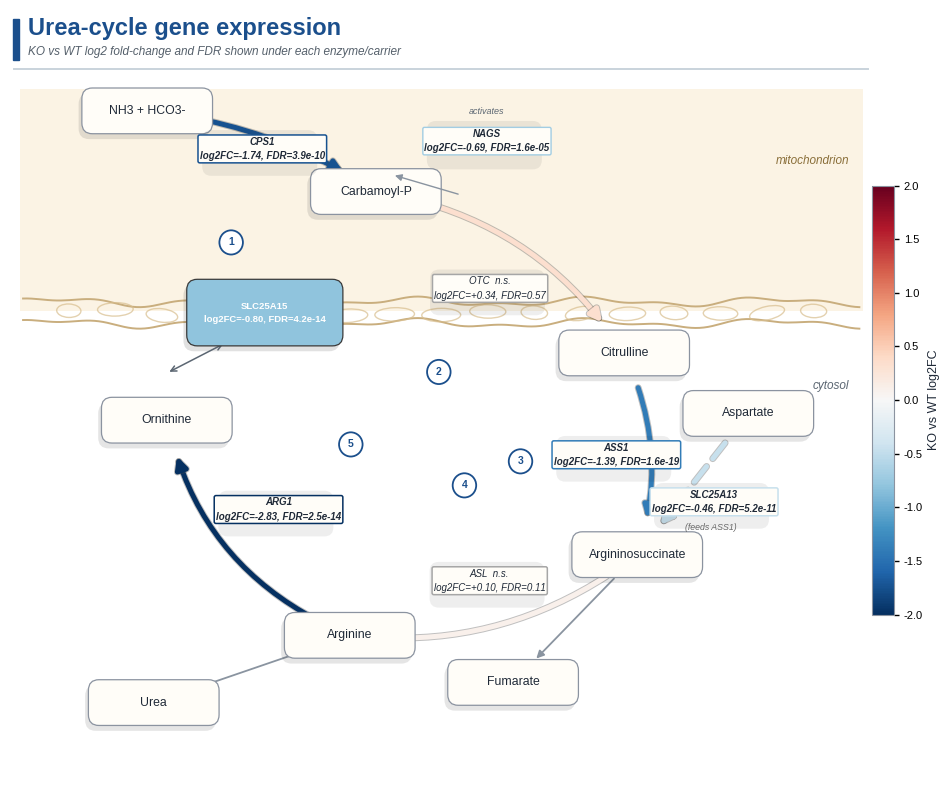

Saved: Fig3E_urea_cycle_diagram.pdf


In [19]:
import numpy as np
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle, Circle, Ellipse
from matplotlib.cm import ScalarMappable
from matplotlib.colors import TwoSlopeNorm
import matplotlib.patheffects as pe

# Same table used for the reviewer bar chart and the Fig S8B overlay below -- no separate read from disk.
df = ug.set_index('gene')
lfc = df['ko_log2FC']; fdr = df['ko_FDR']
norm = TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2); cmap = plt.get_cmap('RdBu_r')   # endpoints match C_DOWN/C_UP
# Narrowed from +/-3: actual range is -2.83..+0.34, so +/-3 left most genes under 60% saturation.
# ARG1 (-2.83) clips to the deepest blue -- appropriate, it's the strongest hit in the panel.
def col(g): return cmap(norm(lfc[g]))
def ns(g):  return not (pd.notna(fdr[g]) and fdr[g] < 0.05)
def fmt_fdr(x): return f"{x:.1e}" if x < 0.01 else f"{x:.2f}"   # compact, WinAnsi-safe (no unicode)

MET = {'Carbamoyl-P':(5.6,8.6),'Citrulline':(9.4,6.2),'Argininosuccinate':(9.6,3.2),
       'Arginine':(5.2,2.0),'Ornithine':(2.4,5.2),'Urea':(2.2,1.0),
       'Aspartate':(11.3,5.3),'Fumarate':(7.7,1.3),'NH3 + HCO3-':(2.1,9.8)}
       # NH3+HCO3- moved further from Carbamoyl-P (was (3.4,9.4)) -- at the original distance the
       # CPS1 arrow's own label sat almost exactly on top of it, hiding the (strongly significant,
       # log2FC=-1.74) arrow entirely behind the label's opaque background.
# order numbers reproduce the numbered-step convention from the BioRender reference figure Ines found
ENZ = [('NH3 + HCO3-','Carbamoyl-P','CPS1',-0.12,1),
       ('Carbamoyl-P','Citrulline','OTC',-0.22,2),
       ('Citrulline','Argininosuccinate','ASS1',-0.20,3),
       ('Argininosuccinate','Arginine','ASL',-0.20,4),
       ('Arginine','Ornithine','ARG1',-0.26,5),
       ('Aspartate','Argininosuccinate','SLC25A13',0.0,None)]
BRANCH = [('Arginine','Urea'),('Argininosuccinate','Fumarate')]

# Figure sized up from the original (6.8,5.6) -- with FC/FDR added under each gene, the labels
# are wider/taller; a bigger canvas at the same data xlim/ylim shrinks their footprint in data
# space (more points per data-unit) rather than requiring every node position to be re-tuned.
fig, ax = plt.subplots(figsize=(9.6, 8.1)); ax.set_xlim(0,13.2); ax.set_ylim(-0.3,11.3); ax.axis('off')
fig.patch.set_facecolor('white')

def node_box(x, y, w, h, **kw):
    return FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle='round,pad=0.02,rounding_size=0.16', **kw)

# ---------- Title block (left accent bar + bold title, echoes the BioRender reference) ----------
ax.add_patch(Rectangle((0.05,10.55),0.09,0.62, color='#1B4F8C', zorder=6))
ax.text(0.28,11.02,'Urea-cycle gene expression', fontsize=17, fontweight='bold', color='#1B4F8C',
        ha='left', va='center', zorder=6)
ax.text(0.28,10.68,'KO vs WT log2 fold-change and FDR shown under each enzyme/carrier',
        fontsize=8.5, color='#55606b', ha='left', va='center', style='italic', zorder=6)
ax.axhline(10.42, 0.005, 0.995, color='#C9D3DC', lw=1.4, zorder=6)

# ---------- Mitochondrion compartment: soft full-width tint above a wavy double-membrane line.
# (Keeps the original convention -- everything above the membrane is "inside the mitochondrion",
# not a self-contained blob -- so CPS1/NAGS/SLC25A15 still read as matrix-resident, matching biology.)
membrane_y = 6.8
ax.add_patch(Rectangle((0.15, membrane_y+0.02), 12.9, 3.3, fc='#FBF3E4', ec='none', zorder=-1))
outer_x = np.linspace(0.2, 13.0, 200)
wobble = 0.05*np.sin(outer_x*2.3) + 0.03*np.sin(outer_x*5.1+1.0)
ax.plot(outer_x, membrane_y+0.16+wobble, color='#C9AE7E', lw=1.4, zorder=0)
ax.plot(outer_x, membrane_y-0.16+wobble, color='#C9AE7E', lw=1.4, zorder=0)
rng = np.random.RandomState(7)
for cx in np.linspace(0.9, 12.3, 17):
    w = rng.uniform(0.35, 0.62)
    ax.add_patch(Ellipse((cx, membrane_y+rng.uniform(-0.05,0.05)), w, 0.20, angle=rng.uniform(-15,15),
                 fc='none', ec='#D8BE8E', lw=1.0, alpha=0.7, zorder=0))
ax.text(12.85, membrane_y+2.35, 'mitochondrion', ha='right', va='top', fontsize=8.5,
        style='italic', color='#8a6f3a', zorder=1)
ax.text(12.85, membrane_y-1.0, 'cytosol', ha='right', va='top', fontsize=8.5,
        style='italic', color='#5b6672', zorder=1)

# ---------- metabolite nodes: soft drop shadow (offset dark copy) + cream card on top ----------
def node(name):
    x,y=MET[name]
    ax.add_patch(node_box(x-0.05,y-0.08,1.96,0.64, fc='#2b2b2b', ec='none', alpha=0.12, zorder=2))
    ax.add_patch(node_box(x,y,1.96,0.64, fc='#FFFDF8', ec='#8b93a0', lw=0.9, zorder=3))
    ax.text(x,y,name, ha='center', va='center', fontsize=8.8, color='#1f2937', zorder=4)
for m in MET: node(m)

for a,b in BRANCH:
    (x1,y1),(x2,y2)=MET[a],MET[b]
    ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2), connectionstyle='arc3,rad=0',
        arrowstyle='-|>', mutation_scale=11, lw=1.3, color='#8a94a0', shrinkA=24, shrinkB=24, zorder=1))

STEP_FACE = '#1B4F8C'
def enzyme(a,b,g,rad,step=None,dashed=False,note=None):
    (x1,y1),(x2,y2)=MET[a],MET[b]; c=col(g)
    ar=FancyArrowPatch((x1,y1),(x2,y2), connectionstyle=f'arc3,rad={rad}', arrowstyle='-|>',
        mutation_scale=17, lw=3.6, color=c, shrinkA=27, shrinkB=27, zorder=2,
        linestyle=(0,(4,2)) if dashed else 'solid', capstyle='round')
    ar.set_path_effects([pe.Stroke(linewidth=5.0, foreground='#4a4a4a', alpha=0.35), pe.Normal()])  # keep light arrows visible
    ax.add_patch(ar)
    mx,my=(x1+x2)/2,(y1+y2)/2; dx,dy=x2-x1,y2-y1; L=np.hypot(dx,dy); nx,ny=-dy/L,dx/L
    lx,ly=mx+nx*(rad*3.2+0.42), my+ny*(rad*3.2+0.42)
    # Text is always black -- only the border/fill communicates the fold-change colour. (NAGS used to
    # set its own font colour to col('NAGS'), which for a moderate fold-change rendered as pale
    # grey-blue on white and was effectively unreadable; kept consistent with the other labels here.)
    txt=g+('  n.s.' if ns(g) else '')
    stats=f"log2FC={lfc[g]:+.2f}, FDR={fmt_fdr(fdr[g])}"
    ax.add_patch(FancyBboxPatch((lx-0.86-0.04,ly-0.32-0.06), 1.72, 0.64,
                 boxstyle='round,pad=0.02,rounding_size=0.14', fc='#2b2b2b', ec='none', alpha=0.08, zorder=4))
    ax.text(lx,ly,txt+"\n"+stats, ha='center', va='center', fontsize=7, fontstyle='italic',
            fontweight=('normal' if ns(g) else 'bold'), color='#1f2937', linespacing=1.55,
            bbox=dict(boxstyle='round,pad=0.18', fc='#FFFDF8', ec=('0.65' if ns(g) else c), lw=1.1), zorder=5)
    if note:
        ax.text(lx-0.05, ly-0.38, note, ha='center', va='center', fontsize=6.3, style='italic',
                color='0.4', zorder=5)
    if step is not None:
        # small numbered badge near the arrow midpoint, matching the BioRender reference's convention
        bx,by = mx+nx*(rad*3.2-1.05), my+ny*(rad*3.2-1.05)
        ax.add_patch(Circle((bx,by), 0.18, fc='white', ec=STEP_FACE, lw=1.3, zorder=6))
        ax.text(bx,by,str(step), ha='center', va='center', fontsize=7.5, fontweight='bold',
                color=STEP_FACE, zorder=7)
for a,b,g,rad,step in ENZ:
    if g == 'SLC25A13':
        enzyme(a,b,g,rad,dashed=True,note='(feeds ASS1)')
    else:
        enzyme(a,b,g,rad,step=step)

ax.add_patch(FancyBboxPatch((7.3-0.86-0.04,9.35-0.34-0.06), 1.72, 0.68,
             boxstyle='round,pad=0.02,rounding_size=0.14', fc='#2b2b2b', ec='none', alpha=0.08, zorder=4))
ax.text(7.3,9.35,f"NAGS\nlog2FC={lfc['NAGS']:+.2f}, FDR={fmt_fdr(fdr['NAGS'])}",
        ha='center', va='center', fontsize=7, fontstyle='italic', fontweight='bold', linespacing=1.55,
        color='#1f2937', bbox=dict(boxstyle='round,pad=0.16', fc='#FFFDF8', ec=col('NAGS'), lw=1.0), zorder=5)
ax.annotate('', xy=(5.85,8.85), xytext=(6.9,8.55), arrowprops=dict(arrowstyle='-|>', lw=1.0, color='#8a94a0'), zorder=4)
ax.text(7.3,9.75,'activates', ha='center', fontsize=6.5, style='italic', color='#5b6672')

ax.add_patch(node_box(3.9-0.05,6.8-0.08,2.35,0.95, fc='#2b2b2b', ec='none', alpha=0.14, zorder=3))
ax.add_patch(node_box(3.9,6.8,2.35,0.95, fc=col('SLC25A15'), ec='#3a3a3a', lw=0.9, zorder=4))
ax.text(3.9,6.8,f"SLC25A15\nlog2FC={lfc['SLC25A15']:+.2f}, FDR={fmt_fdr(fdr['SLC25A15'])}",
        ha='center', va='center', fontsize=6.8, fontweight='bold', color='white', linespacing=1.55, zorder=5)
ax.annotate('', xy=(2.4,5.9), xytext=(3.3,6.35), arrowprops=dict(arrowstyle='<->', lw=1.1, color='#5b6672'))

sm=ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
cb=fig.colorbar(sm, ax=ax, fraction=0.028, pad=0.0, shrink=0.55)
cb.set_label('KO vs WT log2FC', fontsize=9, color='#1f2937'); cb.ax.tick_params(labelsize=8)
cb.outline.set_edgecolor('#8b93a0'); cb.outline.set_linewidth(0.8)

plt.tight_layout()
fig.savefig('Fig3E_urea_cycle_diagram.pdf', bbox_inches='tight', facecolor='white'); plt.show()
print('Saved: Fig3E_urea_cycle_diagram.pdf')


### Reviewer-facing check -- same data as a flat bar chart

Fig 3E was displayed this way in an earlier draft. Kept here, unnumbered, purely so the schematic above can
be checked against the plain numbers gene-by-gene; not referenced in the manuscript.


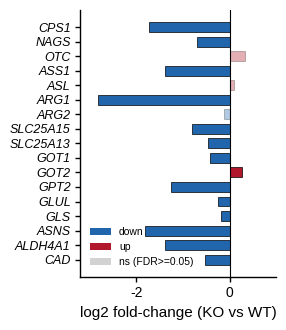

Saved: FigS_urea_cycle_KO_barchart_reviewer.pdf (reviewer check, not in manuscript)


In [20]:
y = np.arange(len(ug))[::-1]          # first gene at top
fig, ax = plt.subplots(figsize=(3.0, 0.2 * len(ug)))
for yi, (_, r) in zip(y, ug.iterrows()):
    lfc = r['ko_log2FC']
    ax.barh(yi, lfc, color=(C_DOWN if lfc < 0 else C_UP), alpha=op(r['ko_FDR']),
            edgecolor='black', linewidth=0.5, height=0.68, zorder=2)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(ug['gene'], fontsize=9, fontstyle='italic')
ax.set_xlabel('log2 fold-change (KO vs WT)', fontsize=AXTITLE)
ax.set_xlim(-3.2, 1.0)
ax.legend(handles=[Patch(facecolor=C_DOWN, label='down'), Patch(facecolor=C_UP, label='up'),
                   Patch(facecolor='0.5', alpha=0.35, label='ns (FDR>=0.05)')],
          frameon=False, fontsize=7.5, loc='lower left')
plt.tight_layout()
fig.savefig('FigS_urea_cycle_KO_barchart_reviewer.pdf', bbox_inches='tight'); plt.show()
print('Saved: FigS_urea_cycle_KO_barchart_reviewer.pdf (reviewer check, not in manuscript)')


### Reviewer companion (unnumbered) -- KO vs SAH-liver concordance

Quantitative companion to the Fig 3E schematic, pairing each gene's SLC38A4-KO fold-change with its
fold-change in SAH liver -- same convention as Fig S8A (leading-edge panels for Fig 3D). Not itself a numbered supplementary
figure -- Fig S8B is the cross-clone GSEA reproducibility forest plot (see
SLC38A4_KO_GSEA_clone_robustness_check.ipynb).


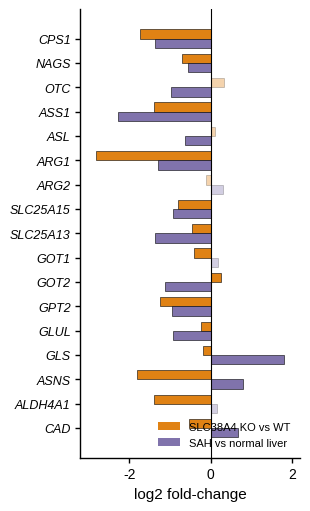

Saved: FigS_urea_cycle_KO_vs_SAH_reviewer.pdf


In [21]:
y = np.arange(len(ug))[::-1]
h = 0.38
fig, ax = plt.subplots(figsize=(3.2, 0.307 * len(ug)))
for yi, (_, r) in zip(y, ug.iterrows()):
    ax.barh(yi + h/2, r['ko_log2FC'],  color=C_KO,  alpha=op(r['ko_FDR']),
            edgecolor='black', linewidth=0.4, height=h, zorder=2)
    ax.barh(yi - h/2, r['sah_log2FC'], color=C_SAH, alpha=op(r['sah_FDR']),
            edgecolor='black', linewidth=0.4, height=h, zorder=2)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(ug['gene'], fontsize=9, fontstyle='italic')
ax.set_xlabel('log2 fold-change', fontsize=AXTITLE)
ax.set_xlim(-3.2, 2.2)
ax.legend(handles=[Patch(facecolor=C_KO, label='SLC38A4 KO vs WT'),
                   Patch(facecolor=C_SAH, label='SAH vs normal liver')],
          frameon=False, fontsize=8, loc='lower right', bbox_to_anchor=(1.0, 0.0))
plt.tight_layout()
fig.savefig('FigS_urea_cycle_KO_vs_SAH_reviewer.pdf', bbox_inches='tight'); plt.show()
print('Saved: FigS_urea_cycle_KO_vs_SAH_reviewer.pdf')
